<a href="https://colab.research.google.com/github/SonnyZhan/llm-distillation-lora/blob/main/llm_lora_distillation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [65]:
!pip install -q -U transformers trl peft accelerate datasets anthropic gradio
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 16.6 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [2]:
import os
from google.colab import userdata
os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
print("Key loaded: ", os.environ["ANTHROPIC_API_KEY"][:2] + "...")

Key loaded:  sk...


In [58]:
import os, torch
import pandas as pd

import anthropic, re, time
from tqdm.auto import tqdm

from datasets import Dataset

from transformers import AutoTokenizer, AutoModelForCausalLM

from sklearn.metrics import accuracy_score, f1_score

from peft import LoraConfig
from trl import SFTTrainer, SFTConfig

In [66]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
print("GPU: ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE, T4 GPU")

GPU:  Tesla T4


In [13]:
train = pd.read_csv("/content/sample_data/train_teacher_labels.csv")
test = pd.read_csv("/content/sample_data/test_teacher_labels.csv")
print("Training len: ", len(train))
print("Testing len: ", len(test))

Training len:  600
Testing len:  400


In [20]:
client = anthropic.Anthropic()
MODEL = "claude-haiku-5-5"

PROMPT = """You are a financial analyst writing a quick note for investors.
Read this sentence from a financial news article.

Reply in exactly this format, nothing else:
label: <positive, negative, or neutral>
analysis: <2 to 3 sentences: what happened, why it matters to an investor
and what to watch next>

Only use facts that are in the sentence. Do not invent numbers, dates, or company details.
Sentence: {sentence}
"""

def parse_label(text):
  text = text.lower()
  match = re.search(r"label:\s*(positive|negative|neutral)", text)
  if match:
    return match.group(1)

  found = [(text.find(l), l) for l in ["positive", "negative", "neutral"] if l in text]
  return min(found)[1] if found else "neutral"

def parse_analysis(text):
  match = re.search(r"analysis:\s*(.+)", text, re.IGNORECASE | re.DOTALL)
  return " ".join(match.group(1).split()) if match else ""

def ask_teacher_with_analysis(sentence):
 res = client.messages.create(
     model=MODEL,
     max_tokens=200,
     thinking={"type": "disabled"},
     messages=[{"role": "user", "content": PROMPT.format(sentence=sentence)}],
     )
 text = "".join(b.text for b in res.content if b.type == "text").strip()
 return parse_label(text), parse_analysis(text)

In [21]:
label, analysis = ask_teacher_with_analysis("The company will lay off 200 employees as demand fails.")
print(label)
print(analysis)

negative
The company is cutting 200 jobs because demand for its products or services has fallen short. For investors, this signals weakening sales and a possible drag on future revenue and margins, though layoffs can also reduce costs. Watch for management's guidance on demand recovery and whether further cuts or revised earnings forecasts follow.


In [23]:
CACHE = "train_with_analysis.csv"
if os.path.exists(CACHE):
  train = pd.read_csv(CACHE)
else:
  answers = [ask_teacher_with_analysis(s) for s in tqdm(train["sentence"])]
  train["r_label"] = [label for label, analysis in answers]
  train["analysis"] = [analysis for label, analysis in answers]
  train.to_csv(CACHE, index=False)

  0%|          | 0/600 [00:00<?, ?it/s]

In [25]:
train["analysis"] = train["analysis"].fillna("")
print("Missing analyses: ", (train["analysis"] == "").sum())

avg_len = int(train["analysis"].str.split().str.len().mean())
print("Average len: ", avg_len, "words")

Missing analyses:  0
Average len:  65 words


In [48]:
#build training data (each with instruction like a chat):
# - one with analysis
# - one without
INSTRUCTION = ("Classify the sentiment of this financial news sentence for an investor."
"Answer with positive, negative, or neutral.")

def make_example(row, with_analysis):
  answer = f"label: {row['r_label']}"
  if with_analysis:
    answer += f"\nanalysis: {row['analysis']}"
  return {
      "prompt": [{"role": "user",
                  "content": f"{INSTRUCTION}\n\n Sentence: {row['sentence']}"}],
      "completion": [{"role": "assistant",
                      "content": answer}],
  }

In [49]:
ds_without_analysis = Dataset.from_list([make_example(row, with_analysis=False)
for _, row in train.iterrows()])

ds_with_analysis = Dataset.from_list([make_example(row, with_analysis=True)
for _, row in train.iterrows()])

print(ds_without_analysis[0]["completion"])
print(ds_with_analysis[0]["completion"][0]["content"])

[{'role': 'assistant', 'content': 'label: positive'}]
label: positive
analysis: Valmet Automotive reported net sales of EUR 85mn and operating profit of EUR 8mn, which indicates the company is generating profit from its revenue. For investors, the key next step is to compare these figures against the prior period and analyst expectations to judge whether margins are improving or under pressure.


In [52]:
#try without fine tuning
BASE = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(BASE)
base_model = AutoModelForCausalLM.from_pretrained(BASE, dtype=torch.float16).to("cuda")

base_model.eval()

def ask_small_model(model, sentence, max_new_tokens=8):
  msg = [{"role": "user", "content": f"{INSTRUCTION}\n\nSentence: {sentence}"}]
  inputs = tokenizer.apply_chat_template(
      msg, add_generation_prompt=True, return_tensors="pt"
  ).to(model.device)
  with torch.no_grad():
    output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

In [54]:
print(ask_small_model(base_model, "Net sales increased by 18% compared to last year", max_new_tokens=40))

Neutral


In [59]:
def eval(model, name, max_token=8):
  preds = []
  start = time.perf_counter()
  for sentence in tqdm(test["sentence"]):
    preds.append(parse_label(ask_small_model(model, sentence, max_token)))

  ms = (time.perf_counter() - start) / len(test) * 1000

  res = {
      "model": name,
      "acc": accuracy_score(test['label_name'], preds),
      "f1": f1_score(test['label_name'], preds, average="macro"),
      "ms_per_sentence": ms,
  }
  return res, preds

In [57]:
base_res, base_preds = eval(base_model, "Small LLm, no training")
print(base_res)
del base_model
torch.cuda.empty_cache()

  0%|          | 0/400 [00:00<?, ?it/s]

{'model': 'Small LLm, no training', 'acc': 0.615, 'f1': 0.25386996904024767, 'ms_per_sentence': 438.5875018249999}


In [61]:
#train with LoRA (twice)
def train_lora(train_ds, out_dir):
  model = AutoModelForCausalLM.from_pretrained(BASE, torch_dtype=torch.float32)

  lora = LoraConfig(
      r=16,
      lora_alpha=32,
      lora_dropout=0.05,
      target_modules="all-linear",
      task_type="CAUSAL_LM",
  )

  args = SFTConfig(
      output_dir=out_dir,
      num_train_epochs=3,
      per_device_train_batch_size=8,
      learning_rate=2e-4,
      logging_steps=10,
      fp16=True,
      gradient_checkpointing=False,
      save_strategy="no",
      report_to="none",
  )

  trainer=SFTTrainer(
      model=model,
      args=args,
      train_dataset=train_ds,
      processing_class=tokenizer,
      peft_config=lora,
  )

  trainer.model.print_trainable_parameters()
  trainer.train()
  trainer.model.eval()
  return trainer.model

In [67]:
model_labels = train_lora(ds_without_analysis, "/content/drive/MyDrive/lora_training_output/")
labels_res, labels_preds = eval(model_labels, "Small LLM + LoRA(labels)")
print(labels_res)

model_labels.save_pretrained("lora_labels")
del model_labels
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
W1117 03:01:31.416000 725 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


Step,Training Loss
10,1.094048
20,4.603986
30,1.609893
40,0.174267
50,0.203602
60,0.178713
70,0.102271
80,0.055844
90,0.043164
100,0.095641


  0%|          | 0/400 [00:00<?, ?it/s]

{'model': 'Small LLM + LoRA(labels)', 'acc': 0.9525, 'f1': 0.9420148098226493, 'ms_per_sentence': 265.35370490749983}


In [68]:
model_analysis = train_lora(ds_with_analysis, "/content/drive/MyDrive/lora_training_output_analysis/")
analysis_res, analysis_preds = eval(model_analysis, "Small LLM + LoRA(labels + analysis)")

print(analysis_res)
model_analysis.save_pretrained("lora_analysis")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


Step,Training Loss
10,1.995325
20,1.520982
30,1.504142
40,1.361044
50,1.331852
60,1.387864
70,1.257388
80,1.161015
90,1.075290
100,0.935177


  0%|          | 0/400 [00:00<?, ?it/s]

{'model': 'Small LLM + LoRA(labels + analysis)', 'acc': 0.9475, 'f1': 0.948508729054371, 'ms_per_sentence': 502.84495370249937}


In [69]:
teacher_res = {
    "model": "Teacher (Claude Haiku)",
    "acc": accuracy_score(test["label_name"], test["teacher_label"]),
    "f1": f1_score(test["label_name"], test["teacher_label"], average="macro"),
    "ms_per_sentence": test["teacher_seconds"].mean() * 1000,
}

results = pd.DataFrame([teacher_res, base_res, labels_res, analysis_res])
results.round(3)

,model,acc,f1,ms_per_sentence
0,Teacher (Claude Haiku),0.955,0.949,576.167
1,"Small LLm, no training",0.615,0.254,438.588
2,Small LLM + LoRA(labels),0.952,0.942,265.354
3,Small LLM + LoRA(labels + analysis),0.948,0.949,502.845


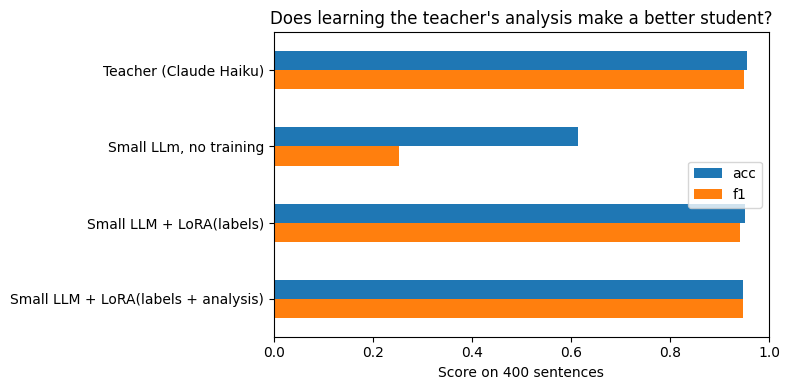

In [72]:
import matplotlib.pyplot as plt

ax = results.set_index("model")[["acc", "f1"]].plot.barh(xlim=(0, 1), figsize=(8, 4))
ax.set_xlabel("Score on 400 sentences")
ax.set_ylabel("")
ax.set_title("Does learning the teacher's analysis make a better student?")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("results_lab2.png", dpi=150)

In [74]:
for sentence in test["sentence"].sample(5, random_state=1):
    print("SENTENCE:", sentence)
    print(ask_small_model(model_analysis, sentence, max_new_tokens=200))
    print("_" * 80)

SENTENCE: The objective is that trading in the shares will commence on May 2 , 2007 .
label: neutral
analysis: The sentence states only that trading in the shares will begin on May 2, 2007, without reporting any price movement, earnings result, or company action. For investors, this is a routine registration date notice rather than a clear signal about value creation or valuation change. Watch for the actual share opening price and any subsequent announcements from the company on that date.
________________________________________________________________________________
SENTENCE: In the second quarter of 2010 , Raute 's net loss narrowed to EUR 123,000 from EUR 1.5 million in the same period of 2009 .
label: positive
analysis: Raute's net loss fell to EUR 123,000 in the second quarter of 2010, down from EUR 1.5 million in the same period of 2009, indicating that the company is now operating more profitably. For investors, this suggests improving profitability over time and may support 

In [75]:
SAVE_DIR = "/content/drive/MyDrive/llm-distillation"
os.makedirs(SAVE_DIR, exist_ok=True)

model_analysis.save_pretrained(f"{SAVE_DIR}/lora_analysis")
!cp -r lora_labels "{SAVE_DIR}/"
!cp train_with_analysis.csv results_lab2.png "{SAVE_DIR}/"
!ls "{SAVE_DIR}"

lora_analysis  lora_labels  results_lab2.png  train_with_analysis.csv
